#### 이진분류 
: 지도학습 <-> 비지도학습 clustering

In [1]:
import torch
import matplotlib.pyplot as plt

#### Step 1 데이터 생성

In [2]:
N = 20

random0 = torch.randn(int(N/2), 1)              # ([10, 1])
random5 = torch.randn(int(N/2), 1) + 5

# print('0: \n', random0)
# print('5: \n', random5)

# data
class1_data = torch.hstack([random0, random5])  # ([10, 2])
class2_data = torch.hstack([random5, random0])

# label
class1_label = torch.ones(int(N/2), 1)          # ([10, 1])
class2_label = torch.zeros(int(N/2), 1)

x = torch.vstack([class1_data, class2_data])    # ([20, 2])
y = torch.vstack([class1_label, class2_label])

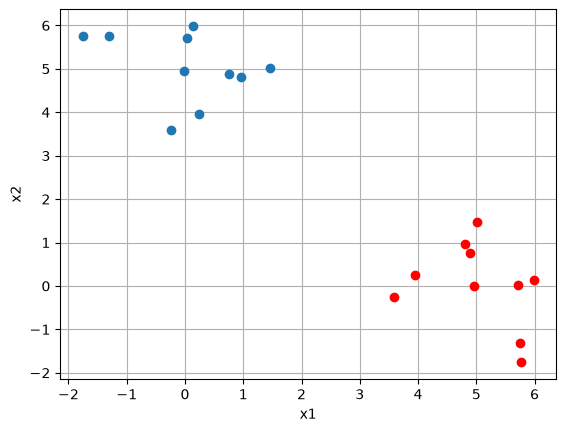

In [3]:
plt.plot(class1_data[:, 0], class1_data[:, 1], 'o')
plt.plot(class2_data[:, 0], class2_data[:, 1], 'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()


#### Step 2. 모델 생성

In [4]:
from torch import nn

class MLP(nn.Module) :
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(2, 100),
                                    nn.Sigmoid(),
                                    nn.Linear(100, 1),
                                    nn.Sigmoid()
                                    )
    def forward(self, x):   # nn.Module에서 forward는 자동생성하도록 정의, 이름 동일하게 생성 필요함
        x = self.linear(x)
        return x

In [5]:
# from torch import nn

# class MLP(nn.Module) :
#     def __init__(self):
#         super().__init__()

#         self.linear = nn.Sequential(nn.Linear(2, 100),      # 복잡한 데이터라면 층을 더 많이 생성할 수록 성능이 올라감
#                                     nn.Sigmoid(),
#                                     nn.Linear(100, 100),
#                                     nn.Sigmoid(),
#                                     nn.Linear(100, 100),
#                                     nn.Sigmoid(),
#                                     nn.Linear(100, 1),
#                                     nn.Sigmoid()
#                                     )
#     def forward(self, x):   # nn.Module에서 forward는 자동생성하도록 정의, 이름 동일하게 생성 필요함
#         x = self.linear(x)
#         return x

In [6]:
model = MLP()
print(model)

b = model(torch.randn(5,2))
print(b.shape)
print(b)


MLP(
  (linear): Sequential(
    (0): Linear(in_features=2, out_features=100, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=100, out_features=1, bias=True)
    (3): Sigmoid()
  )
)
torch.Size([5, 1])
tensor([[0.4285],
        [0.4182],
        [0.4375],
        [0.4333],
        [0.4764]], grad_fn=<SigmoidBackward0>)


#### Step 3. 모델 학습

In [7]:
from torch import optim

In [ ]:
LR = 1e-1   # 0.1
EPOCH = 100

optimizer = optim.SGD(model.parameters(), lr=LR)
criterion = nn.BCELoss()

loss_history = []

model.train()   # 학습 모드로 전환 - dropout 가능 / 테스트모드 - dropout 불가
# Dropout은 학습할 때 일부 뉴런의 출력을 무작위로 0으로 만들어 과적합을 줄이는 방법
for ep in range(EPOCH):
    
    # 예측값
    y_hat = model(x)
    
    # loss 구하기
    loss = criterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history += [loss.item()]

    # print
    # print(f'Epoch: {ep+1}, train loss: {loss.item():.4f}')
    # print()

Text(0, 0.5, 'Loss')

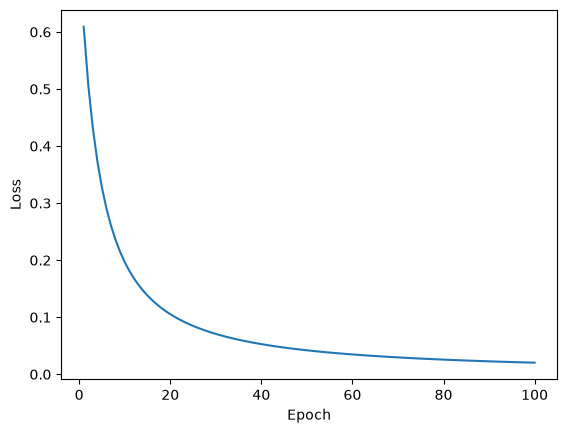

In [9]:
# 학습 곡선
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')

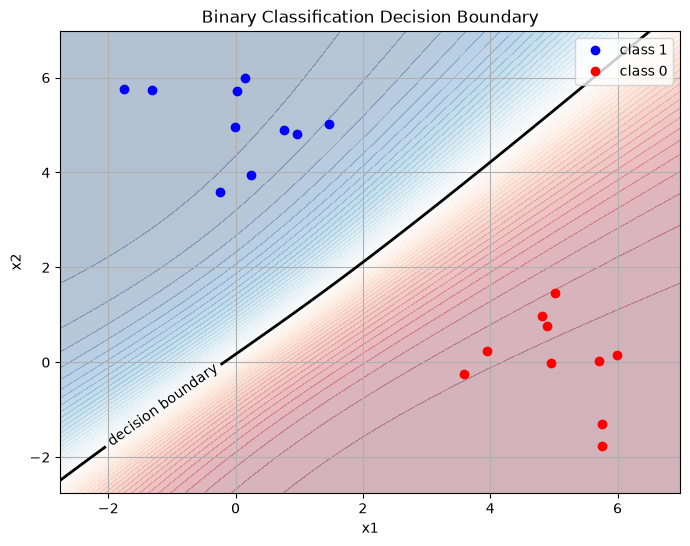

In [10]:
import numpy as np

# -----------------------------
# 4. 결정경계(decision boundary) 그리기
# -----------------------------
model.eval()

# 그래프 범위 설정
x_min, x_max = x[:, 0].min().item() - 1, x[:, 0].max().item() + 1
y_min, y_max = x[:, 1].min().item() - 1, x[:, 1].max().item() + 1

# 촘촘한 grid 생성
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

# grid를 모델 입력 형태로 변환
grid = np.c_[xx.ravel(), yy.ravel()]   # (200*200, 2)
grid_tensor = torch.tensor(grid, dtype=torch.float32)

# grid 전체에 대한 예측
with torch.no_grad():
    pred = model(grid_tensor).reshape(xx.shape).numpy()

# -----------------------------
# 5. 시각화
# -----------------------------
plt.figure(figsize=(8, 6))

# 배경색으로 분류영역 표시(선택사항)
plt.contourf(xx, yy, pred, levels=50, alpha=0.3, cmap='RdBu')

# 결정경계: 예측확률 0.5인 선
contour = plt.contour(xx, yy, pred, levels=[0.5], colors='black', linewidths=2)
plt.clabel(contour, fmt='decision boundary', fontsize=10)

# 원래 데이터 표시
plt.plot(class1_data[:, 0], class1_data[:, 1], 'bo', label='class 1')
plt.plot(class2_data[:, 0], class2_data[:, 1], 'ro', label='class 0')

plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Binary Classification Decision Boundary')
plt.legend()
plt.grid()
plt.show()

#### step 4. 모델 테스트

tensor([[-10.0000, -10.0000, -10.0000, -10.0000, -10.0000, -10.0000, -10.0000,
         -10.0000, -10.0000, -10.0000, -10.0000, -10.0000, -10.0000, -10.0000,
         -10.0000, -10.0000, -10.0000, -10.0000, -10.0000, -10.0000, -10.0000,
         -10.0000, -10.0000, -10.0000, -10.0000, -10.0000, -10.0000, -10.0000,
         -10.0000, -10.0000],
        [ -9.3103,  -9.3103,  -9.3103,  -9.3103,  -9.3103,  -9.3103,  -9.3103,
          -9.3103,  -9.3103,  -9.3103,  -9.3103,  -9.3103,  -9.3103,  -9.3103,
          -9.3103,  -9.3103,  -9.3103,  -9.3103,  -9.3103,  -9.3103,  -9.3103,
          -9.3103,  -9.3103,  -9.3103,  -9.3103,  -9.3103,  -9.3103,  -9.3103,
          -9.3103,  -9.3103],
        [ -8.6207,  -8.6207,  -8.6207,  -8.6207,  -8.6207,  -8.6207,  -8.6207,
          -8.6207,  -8.6207,  -8.6207,  -8.6207,  -8.6207,  -8.6207,  -8.6207,
          -8.6207,  -8.6207,  -8.6207,  -8.6207,  -8.6207,  -8.6207,  -8.6207,
          -8.6207,  -8.6207,  -8.6207,  -8.6207,  -8.6207,  -8.6207,  -

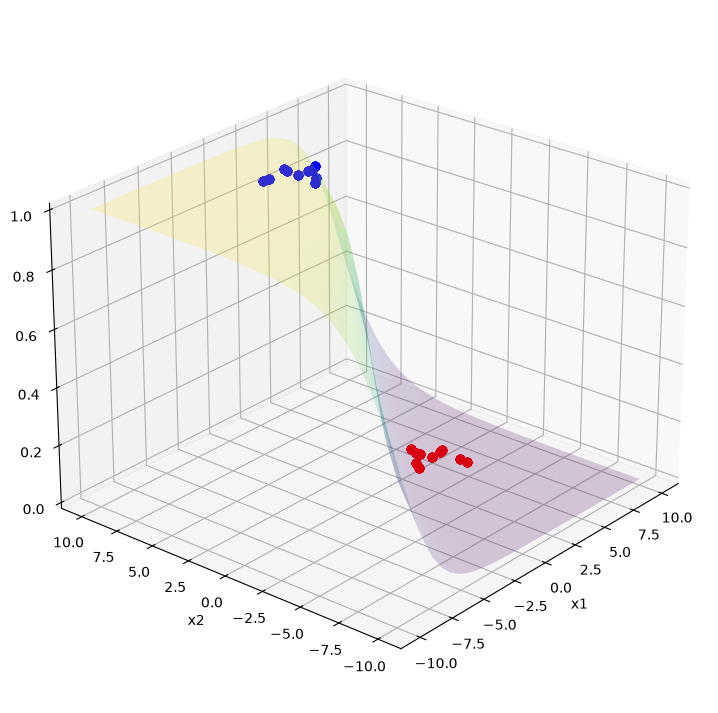

In [ ]:
x1_test = torch.linspace(-10 ,10 , 30)  # X 축
x2_test = torch.linspace(-10, 10, 30)   # Y 축

X1_test, X2_test = torch.meshgrid(x1_test, x2_test) # 좌표 생성 (30, 30)
print(X1_test)

X_test = torch.cat([X1_test.unsqueeze(dim=2), X2_test.unsqueeze(dim=2)], dim=2) # 3차원으로 변환 (30, 30, 1), 3차원에서 면으로 투영시키기 위함

model.eval()
with torch.no_grad():
    y_hat = model(X_test)   # 예측값 = 높이를 생성 (30, 30, 1(높이))

Y_hat = y_hat.squeeze() # (30,30)으로 다시 축소, 그래프에 투영

plt.figure(figsize= (10,9))
ax= plt.axes(projection='3d')       # 3차원의 높이: 입력 좌표가 모델을 통과해 출력받은 예측값이 1에 가까우면 클래스 1로, 0에 가까우면 클래스 2로 분류
ax.view_init(elev= 25, azim= -140)  # 그래프를 바라보는 카메라 각도
# - elev=25: 수평면보다 25° 위에서 내려다봅니다.
# - azim=-140: z축 주위로 카메라를 회전한 방향입니다

ax.plot_surface(X1_test, X2_test, Y_hat.numpy(), cmap='viridis', alpha=0.2) # 테스트 결과(Y_hat의 900개 좌표)를 '면'으로 3차원에 투영 : NOTE 모델(weight와 bias)를 투영시킨게 아님
plt.plot(class1_data[:,0], class1_data[:,1], class1_label, 'bo')    # 분류1 점 투영
plt.plot(class2_data[:,0], class2_data[:,1], class2_label, 'ro')    # 분류2 점 투영
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()
# 모델의 적합 정도는 테스트 면 의 기울기가 어느정도 완만한지로 해석됨(가파름: 과적합, 완만함: 과소적합)
# 면의 기울기: 입력이 조금 바뀔 때 예측확률이 얼마나 빠르게 바뀌는가
# 학습점 하나를 맞추려고 표면에 작은 봉우리·골짜기가 생김 -> 과적합